# 13 · Fine-tuning with Hugging Face: SFT, LoRA and distillation

A pretrained *instruct* model already chats, but it does not know **your** task, your output format or your conventions. Supervised fine-tuning (SFT) teaches it from (prompt → answer) examples.

| stage | data | objective | library |
|---|---|---|---|
| **SFT** (this notebook) | (prompt → response) pairs | next-token loss on the *response only* | `trl.SFTTrainer` |
| **LoRA** (this notebook) | same | same, but train small low-rank adapters | `peft.LoraConfig` |
| **distillation** (this notebook) | prompts labelled by a bigger teacher | SFT on the teacher's answers | `trl.SFTTrainer` |
| preferences (DPO) | (prompt, chosen, rejected) | prefer chosen over rejected | `trl.DPOTrainer` (notebook 14) |
| RL with verifiable rewards (GRPO) | prompts + a checker | maximize reward | `trl.GRPOTrainer` (notebook 14) |

**The task.** Turn a booking request written by a person into strict JSON:

`"Can you reserve Casa Lola for three people this Friday at 8:30 pm? It's under Rocio."` → `{"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "friday", "time": "20:30"}`

It looks easy, but the format is strict: `people` must be an integer (people write "three"), `day` lowercase, and `time` in 24-hour format (people write "8:30 pm" or "8 in the evening"). That last conversion is the hard part for a small model, and you will see it in every result below.

**The model.** `HuggingFaceTB/SmolLM2-135M-Instruct` (135 M parameters), small enough to fine-tune in a minute on a laptop GPU. The same code works unchanged for a 7B model on a bigger GPU.

**Plan:** chat templates and loss masking → baseline → full SFT vs LoRA → the "new special token" trap → rank ablation → distillation from a 360M teacher → evaluation.

## Background: from a pretrained model to a task specialist

### Supervised fine-tuning is maximum likelihood on demonstrations

A causal language model $\pi_\theta$ defines a probability for every continuation $y = (y_1, \dots, y_T)$ of a prompt $x$, one token at a time: $\pi_\theta(y \mid x) = \prod_t \pi_\theta(y_t \mid x, y_{<t})$. Pre-training maximises this likelihood on raw web text. SFT uses *exactly the same objective*, only on a curated dataset $\mathcal{D}$ of (prompt, ideal answer) pairs, and only on the answer tokens:

$$\mathcal{L}_{\text{SFT}}(\theta) = -\,\mathbb{E}_{(x,y)\sim\mathcal{D}} \sum_{t=1}^{|y|} \log \pi_\theta(y_t \mid x, y_{<t})$$

Two properties of this objective explain most of what you will see in this notebook.

- **Teacher forcing.** During training the model always conditions on the *correct* previous tokens $y_{<t}$. At inference it conditions on its *own* previous tokens. A small early mistake (a wrong hour) puts it in a state it never saw during training, and nothing in the loss taught it how to recover. This mismatch is called **exposure bias**. It is one of the motivations for the preference and RL methods of notebook 14, which train on the model's own samples.
- **Imitation, not judgement.** SFT is behaviour cloning: the model learns to produce answers that look like the demonstrations, including their mistakes. It receives no signal that one wrong answer is worse than another, and no signal about answers it was never shown. Data quality is therefore the main lever. The LIMA paper (Zhou et al., 2023) argued that a thousand carefully chosen examples can be enough to teach the *format* of helpful answers, because most of the knowledge is already in the pretrained weights (their "superficial alignment hypothesis"; how far it holds is debated).

### What fine-tuning is good at

Fine-tuning reliably teaches **form**: an output format, a style, a label set, a set of conventions, and how to apply a rule the base model already half-knows (here, converting "8:30 pm" to "20:30"). It is a poor way to add **new facts**: Gekhman et al. (2024) found that examples whose facts the model did not already know are learned slowly and, once learned, increase hallucination on other questions. For knowledge that changes, retrieval (notebook 18) is usually the better tool.

| approach | changes | good for | weak at | cost |
|---|---|---|---|---|
| prompting / few-shot | nothing (context only) | quick iteration, many tasks with one model | long, strict formats; every call pays for the examples | tokens per call |
| RAG | the context, from a store you control | facts that change, citations, access control | teaching a new behaviour or format | an index + retrieval latency |
| SFT (full or LoRA) | the weights | formats, style, narrow skills, shorter prompts | adding new knowledge; needs labelled data | a training run, a model to serve |
| distillation | the weights of a smaller model | cutting serving cost once a big model works | the student inherits the teacher's errors | teacher inference + a training run |

In practice these are combined: a fine-tuned model that follows your format, fed with retrieved context.

### The cost of full fine-tuning, and the parameter-efficient family

Updating every weight means storing a gradient and optimizer state for every weight (section 4.1 does the accounting). It also means one full copy of the model per task. **Parameter-efficient fine-tuning (PEFT)** keeps the pretrained weights frozen and trains a small number of new parameters:

| method | what is trained | inference cost | reference |
|---|---|---|---|
| adapters | small bottleneck MLPs inserted in each layer | extra layers on every forward pass | Houlsby et al., 2019 |
| prefix / prompt tuning | learned "virtual tokens" prepended to the keys and values or to the input | longer effective sequence | Li & Liang, 2021; Lester et al., 2021 |
| **LoRA** | a low-rank update $BA$ added to existing weight matrices | **zero after merging** | Hu et al., 2021 |
| QLoRA | LoRA on top of a 4-bit quantized frozen base | as LoRA (base stays quantized or is merged) | Dettmers et al., 2023 |
| DoRA | LoRA applied to the direction of each weight, with a separately learned magnitude | zero after merging | Liu et al., 2024 |

LoRA became the default for three reasons: it adds no latency once merged, it matches full fine-tuning on many narrow tasks, and it is supported everywhere (`peft`, TRL, vLLM and most serving stacks can load several adapters on one base model). Its theoretical motivation is the observation that fine-tuning has a low **intrinsic dimension**: Aghajanyan et al. (2021) showed that a pretrained model can be fine-tuned well by optimizing a few hundred or thousand parameters projected into the full weight space. If the useful update lives in a small subspace, there is no need to parameterize all of it.

### Key papers

- Hu et al., 2021. *LoRA: Low-Rank Adaptation of Large Language Models.*
- Aghajanyan, Gupta & Zettlemoyer, 2021. *Intrinsic Dimensionality Explains the Effectiveness of Language Model Fine-Tuning.*
- Dettmers et al., 2023. *QLoRA: Efficient Finetuning of Quantized LLMs.*
- Zhou et al., 2023. *LIMA: Less Is More for Alignment.*
- Gekhman et al., 2024. *Does Fine-Tuning LLMs on New Knowledge Encourage Hallucinations?*
- Biderman et al., 2024. *LoRA Learns Less and Forgets Less.*
- Hinton, Vinyals & Dean, 2015. *Distilling the Knowledge in a Neural Network.*
- Kim & Rush, 2016. *Sequence-Level Knowledge Distillation.*

In [1]:
import os
# This notebook trains eleven models in one process, and the 4-bit model of section 4.3 leaves ~0.1 GB behind on the GPU.
# A 2 GB budget fits every run and still leaves room for Ollama (~2.3 GB) on a 6 GB card. Notebooks 11 and 14 keep 1.5 GB.
os.environ.setdefault("VRAM_BUDGET_GB", "2")

In [2]:
import os, sys, json, time, random, re, gc, copy, tempfile, warnings
ROOT = os.path.abspath(".")
while not os.path.isdir(os.path.join(ROOT, "llm_edu_suite")) and os.path.dirname(ROOT) != ROOT:
    ROOT = os.path.dirname(ROOT)                    # walk up from notebooks/<topic>/ to the repo root
sys.path.insert(0, ROOT)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import torch
import transformers, peft, trl, datasets
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed
transformers.utils.logging.set_verbosity_error()   # keep the notebook output to what we print ourselves
transformers.utils.logging.disable_progress_bar()
datasets.disable_progress_bars()
import huggingface_hub; huggingface_hub.utils.logging.set_verbosity_error()
set_seed(0)

device = "cuda" if torch.cuda.is_available() else "cpu"
BF16 = device == "cuda" and torch.cuda.is_bf16_supported()
DTYPE = torch.bfloat16 if BF16 else torch.float32
# We share the GPU with Ollama, so we give this notebook a fixed VRAM budget. Going over it raises an
# out-of-memory error right away instead of silently spilling into (very slow) system RAM.
VRAM_BUDGET_GB = float(os.environ.get("VRAM_BUDGET_GB", 1.5))
if device == "cuda":
    total = torch.cuda.get_device_properties(0).total_memory / 1e9
    torch.cuda.set_per_process_memory_fraction(min(1.0, VRAM_BUDGET_GB / total))
    print(f"GPU: {torch.cuda.get_device_name(0)} ({total:.1f} GB), bf16: {BF16}, budget for this notebook: {VRAM_BUDGET_GB} GB")
else:
    print("No GPU found: running on CPU (expect it to be much slower)")
print("torch", torch.__version__, "| transformers", transformers.__version__, "| peft", peft.__version__, "| trl", trl.__version__)

def from_pretrained(cls, name, **kw):
    """Load from the local Hugging Face cache when the model is there, and download it otherwise."""
    try:
        return cls.from_pretrained(name, local_files_only=True, **kw)
    except OSError:
        return cls.from_pretrained(name, **kw)

def free():
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()

def reset_peak():
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()

def peak_gb():
    return torch.cuda.max_memory_allocated() / 1e9 if device == "cuda" else float("nan")

W1109 18:21:05.866000 29924 .venv\Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


GPU: NVIDIA GeForce RTX 3060 Laptop GPU (6.4 GB), bf16: True, budget for this notebook: 2.0 GB
torch 2.14.1+cu130 | transformers 5.22.2 | peft 0.21.2 | trl 1.17.1


## 1. The task and the data

We generate the data, so we know the right answer for every example and can measure exactly. The **test set uses names and restaurants that never appear in training**, so a model that memorised the training set gets no credit. 300 labelled examples is our whole labelled budget (think of it as what a team can label by hand in an afternoon).

In [3]:
TRAIN_NAMES = ["Ana", "Luis", "Marta", "Pablo", "Sofia", "Diego", "Elena", "Jorge", "Lucia", "Carlos", "Irene", "Tomas",
               "Nuria", "Raul", "Clara", "Hugo", "Paula", "Adrian", "Sara", "Mario", "Laura", "Ivan", "Julia", "Victor"]
TEST_NAMES = ["Beatriz", "Oscar", "Alba", "Marcos", "Noelia", "Gonzalo", "Rocio", "Felipe", "Ines", "Samuel"]
TRAIN_PLACES = ["Casa Pepe", "La Tagliatella", "Sushi Zen", "El Faro", "Burger Hub", "Taco Loco", "Le Petit Bistro",
                "Green Garden", "La Brasa", "Mar Azul", "Pizza Napoli", "The Golden Duck", "Curry House", "El Rincon"]
TEST_PLACES = ["Asador Toro", "Bella Vista", "Noodle Bar", "Casa Lola", "The Oak Room", "Kebab Palace", "Ramen Ya"]
DAYS = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]
NUM_WORDS = {2: "two", 3: "three", 4: "four", 5: "five", 6: "six", 7: "seven", 8: "eight", 9: "nine", 10: "ten"}
TEMPLATES = [
    "Hi, I'd like to book a table for {people} at {place} on {day} at {time}. The name is {name}.",
    "Can you reserve {place} for {people} people this {day} at {time}? It's under {name}.",
    "{name} here. Table for {people} at {place}, {day}, {time} please.",
    "Please make a reservation at {place}: {people} guests, {day} {time}, name {name}.",
    "We are {people}. Could we get a table at {place} on {day} around {time}? Booking for {name}.",
    "Book {place} for {name}, party of {people}, {day} at {time}.",
]
SYSTEM = "Extract the booking as JSON: name, restaurant, people (int), day (lowercase), time (24h HH:MM)."
FIELDS = ["name", "restaurant", "people", "day", "time"]

def time_text(h, m, rng):
    """The same time written the way people write it: 8pm, 8:30 pm, 20:30 or 8 in the evening."""
    h12 = h - 12 if h > 12 else h
    return [f"{h12}{':%02d' % m if m else ''}pm", f"{h12}:{m:02d} pm", f"{h:02d}:{m:02d}",
            f"{h12}{':%02d' % m if m else ''} in the evening"][rng.randrange(4)]

def make_booking(rng, names, places):
    people, h, m = rng.randint(2, 10), rng.randint(13, 22), rng.choice([0, 0, 15, 30, 45])
    target = {"name": rng.choice(names), "restaurant": rng.choice(places), "people": people,
              "day": rng.choice(DAYS), "time": f"{h:02d}:{m:02d}"}
    text = rng.choice(TEMPLATES).format(
        people=NUM_WORDS[people] if rng.random() < 0.4 else str(people), place=target["restaurant"],
        day=target["day"].capitalize() if rng.random() < 0.7 else target["day"], time=time_text(h, m, rng), name=target["name"])
    return text, target

def booking_examples(n, seed, split="train"):
    rng = random.Random(seed)
    names, places = (TRAIN_NAMES, TRAIN_PLACES) if split == "train" else (TEST_NAMES, TEST_PLACES)
    return [make_booking(rng, names, places) for _ in range(n)]

def to_prompt_completion(text, target, system=SYSTEM):
    """TRL's conversational prompt-completion format: the loss will only cover the completion."""
    return {"prompt": [{"role": "system", "content": system}, {"role": "user", "content": text}],
            "completion": [{"role": "assistant", "content": json.dumps(target)}]}

train_pairs = booking_examples(300, seed=0)                 # our labelled budget
test_pairs = booking_examples(40, seed=1, split="test")     # held out: unseen names and restaurants
train_rows = [to_prompt_completion(x, y) for x, y in train_pairs]
for x, y in train_pairs[:3]:
    print(x, "\n   ->", json.dumps(y))

Please make a reservation at La Brasa: 8 guests, thursday 7 in the evening, name Lucia. 
   -> {"name": "Lucia", "restaurant": "La Brasa", "people": 8, "day": "thursday", "time": "19:00"}
Can you reserve Sushi Zen for 7 people this Wednesday at 22:00? It's under Paula. 
   -> {"name": "Paula", "restaurant": "Sushi Zen", "people": 7, "day": "wednesday", "time": "22:00"}
Hi, I'd like to book a table for 10 at La Tagliatella on Saturday at 10 in the evening. The name is Carlos. 
   -> {"name": "Carlos", "restaurant": "La Tagliatella", "people": 10, "day": "saturday", "time": "22:00"}


**Metrics** (computed on the 40 held-out requests, greedy decoding):
- **JSON valid**: the reply contains a JSON object that parses.
- **exact match**: every field is right. This is the number that matters in production, because one wrong field is a wrong booking.
- **field accuracy**: the fraction of fields that are right (partial credit), plus the accuracy of `time` alone, the hardest field.

In [4]:
def parse_json(reply):
    m = re.search(r"\{.*\}", reply, re.S)
    try:
        obj = json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        return None
    return obj if isinstance(obj, dict) else None

def score(replies, pairs=None):
    pairs = pairs or test_pairs
    objs = [parse_json(r) for r in replies]
    return {"valid": np.mean([o is not None for o in objs]),
            "exact": np.mean([o == y for o, (_, y) in zip(objs, pairs)]),
            "fields": np.mean([np.mean([(o or {}).get(k) == v for k, v in y.items()]) for o, (_, y) in zip(objs, pairs)]),
            "time": np.mean([(o or {}).get("time") == y["time"] for o, (_, y) in zip(objs, pairs)])}

@torch.no_grad()
def generate(model, tok, prompts, max_new_tokens=64, batch_size=20, skip_special_tokens=True):
    """Greedy replies for a list of chat prompts, in batches (left padding so every prompt ends at the same position)."""
    model.eval(); tok.padding_side = "left"; out = []
    for i in range(0, len(prompts), batch_size):
        enc = tok.apply_chat_template(prompts[i:i + batch_size], add_generation_prompt=True, return_tensors="pt",
                                      return_dict=True, padding=True).to(model.device)
        ids = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=tok.pad_token_id)
        out += tok.batch_decode(ids[:, enc["input_ids"].shape[1]:], skip_special_tokens=skip_special_tokens)
    return out

RESULTS = {}      # name -> metrics, filled by evaluate()
def evaluate(model, tok, name, prompts=None, show=0):
    replies = generate(model, tok, prompts or [to_prompt_completion(x, y)["prompt"] for x, y in test_pairs])
    RESULTS[name] = s = score(replies)
    print(f"{name:34s} valid {100*s['valid']:5.1f}% | exact {100*s['exact']:5.1f}% | fields {100*s['fields']:5.1f}% | time {100*s['time']:5.1f}%")
    for r in replies[:show]:
        print("    ", r[:150].replace("\n", " "))
    return replies

## 2. Chat templates and loss masking

An instruct model was trained on conversations rendered with a **chat template**: special tokens mark who is speaking. SmolLM2 uses the ChatML format (`<|im_start|>role ... <|im_end|>`). Fine-tuning must use *exactly* the same template the model will see at inference, so we never build the strings by hand: `tokenizer.apply_chat_template` does it.

In [5]:
MODEL = "HuggingFaceTB/SmolLM2-135M-Instruct"
tok = from_pretrained(AutoTokenizer, MODEL)
ex = train_rows[0]
print(tok.apply_chat_template(ex["prompt"] + ex["completion"], tokenize=False))

<|im_start|>system
Extract the booking as JSON: name, restaurant, people (int), day (lowercase), time (24h HH:MM).<|im_end|>
<|im_start|>user
Please make a reservation at La Brasa: 8 guests, thursday 7 in the evening, name Lucia.<|im_end|>
<|im_start|>assistant
{"name": "Lucia", "restaurant": "La Brasa", "people": 8, "day": "thursday", "time": "19:00"}<|im_end|>


**Loss masking.** We want the model to learn to *write the answer*, not to predict the system prompt or the user's sentence (that would waste capacity and teach it to imitate users). So the labels of every prompt token are set to `-100`, which PyTorch's cross-entropy ignores, and the loss only covers the assistant's reply **including its end-of-turn token `<|im_end|>`**, so the model also learns when to stop.

In terms of the objective above, masking turns the joint likelihood $\log \pi(x, y)$ into the conditional likelihood $\log \pi(y \mid x)$: we model the answer *given* the prompt, which is exactly what we will ask of the model at inference. With short answers and long prompts (here a long system prompt and a short JSON) the difference is large, because without masking most of the gradient would come from the prompt. Whether the prompt loss is always useless is debated: Shi et al. (2024, *Instruction Tuning With Loss Over Instructions*) report gains from keeping it when the answers are very short and the data is small, as a form of regularization. Completion-only loss remains the standard default.

In TRL you get this by giving the dataset a `prompt` / `completion` split (`completion_only_loss`, the default for that format). For multi-turn chats there is `SFTConfig(assistant_only_loss=True)`, which needs a chat template with `{% generation %}` markers (TRL ships patched templates for common model families).

Under the hood it is just this:

In [6]:
def completion_labels(tokenizer, prompt, completion):
    """Tokenize prompt + completion with the chat template; mask every prompt token with -100."""
    prompt_ids = tokenizer.apply_chat_template(prompt, add_generation_prompt=True, tokenize=True, return_dict=True)["input_ids"]
    full_ids = tokenizer.apply_chat_template(prompt + completion, tokenize=True, return_dict=True)["input_ids"]
    assert full_ids[:len(prompt_ids)] == prompt_ids          # the prompt must be a prefix of the full conversation
    return full_ids, [-100] * len(prompt_ids) + full_ids[len(prompt_ids):]

ids, labels = completion_labels(tok, ex["prompt"], ex["completion"])
n_learn = sum(l != -100 for l in labels)
print(f"{len(ids)} tokens, {n_learn} with a loss ({100*n_learn/len(ids):.0f}%), {len(ids) - n_learn} masked\n")
n_prompt = len(ids) - n_learn
show = list(range(n_prompt - 8, n_prompt + 6)) + list(range(len(ids) - 4, len(ids)))
print("around the prompt/answer boundary and at the end:   · = masked (label -100)   ✓ = trained")
for i in show:
    print(f"   {i:3d} {'✓' if labels[i] != -100 else '·'}  {tok.decode([ids[i]])!r}" + ("   ..." if i == n_prompt + 5 else ""))

110 tokens, 42 with a loss (38%), 68 masked

around the prompt/answer boundary and at the end:   · = masked (label -100)   ✓ = trained
    60 ·  'ia'
    61 ·  '.'
    62 ·  '<|im_end|>'
    63 ·  '\n'
    64 ·  '<|im_start|>'
    65 ·  'ass'
    66 ·  'istant'
    67 ·  '\n'
    68 ✓  '{"'
    69 ✓  'name'
    70 ✓  '":'
    71 ✓  ' "'
    72 ✓  'Luc'
    73 ✓  'ia'   ...
   106 ✓  '0'
   107 ✓  '"}'
   108 ✓  '<|im_end|>'
   109 ✓  '\n'


Let's check that TRL builds exactly the same labels. `SFTTrainer` tokenizes the dataset when it is created, so we can inspect its `train_dataset` before training anything.

In [7]:
from datasets import Dataset
from trl import SFTConfig, SFTTrainer
from transformers import PrinterCallback

OUT = os.path.join(tempfile.gettempdir(), "llm_edu_07")
base = from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device)
probe = SFTTrainer(model=base, args=SFTConfig(output_dir=OUT, report_to="none", max_length=256, bf16=BF16, gradient_checkpointing=False),
                   train_dataset=Dataset.from_list(train_rows), processing_class=tok)
row = probe.train_dataset[0]
print("columns after TRL's preprocessing:", probe.train_dataset.column_names)
print("TRL's labels == our labels:", row["input_ids"] == ids and row["labels"] == labels)
del probe

columns after TRL's preprocessing: ['prompt', 'completion', 'input_ids', 'labels']
TRL's labels == our labels: True


## 3. Baseline: the instruct model before fine-tuning

Always measure the model before training, on the same test set, with the best prompt you can write. Here we try zero-shot (system prompt only) and **few-shot** (four solved examples in the conversation). Few-shot is the strong baseline that fine-tuning has to beat.

In [8]:
def few_shot_prompt(text, shots=booking_examples(4, seed=123)):
    msgs = [{"role": "system", "content": SYSTEM}]
    for x, y in shots:
        msgs += [{"role": "user", "content": x}, {"role": "assistant", "content": json.dumps(y)}]
    return msgs + [{"role": "user", "content": text}]

_ = evaluate(base, tok, "baseline zero-shot", show=1)
_ = evaluate(base, tok, "baseline few-shot", prompts=[few_shot_prompt(x) for x, _ in test_pairs], show=2)
del base; free()

baseline zero-shot                 valid   5.0% | exact   0.0% | fields   2.0% | time   0.0%
     Asador Toro: 4 guests, Thursday 10:00 pm, name Noelia.


baseline few-shot                  valid 100.0% | exact  17.5% | fields  73.0% | time  25.0%
     {"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "Thursday", "time": "10:00 pm"}
     {"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "Friday", "time": "8:00 pm"}


Zero-shot, the 135M model almost never produces JSON (5 %): it mostly rephrases the request. With four examples it always produces valid JSON, but the normalization is often wrong (`"Thursday"`, `"10:00 pm"`): 17.5 % exact. That is our bar.

## 4. Full fine-tuning vs LoRA

### 4.1 How much memory does full fine-tuning need?

With mixed precision and AdamW, every trainable parameter costs about **16 bytes**: fp32 weight (4) + gradient (4) + Adam's two moments (8), before activations. For 135 M parameters that is 2.2 GB, already above this notebook's budget; for a 7B model it is 112 GB. Two standard ways out:
- cheaper optimizer state and bf16 weights (here: bf16 weights + **Adafactor**, which stores a factored second moment and no first moment), or
- train far fewer parameters: **LoRA**.

The 16-byte figure is the standard accounting from the ZeRO paper (Rajbhandari et al., 2020), which splits it slightly differently for mixed-precision training: a 16-bit copy of the weights (2 bytes) and of the gradients (2), plus an fp32 master copy of the weights (4) and Adam's first and second moments (4 + 4). Either way, for $N$ parameters the training state is about $16N$ bytes, and **activations come on top**: they grow with batch size × sequence length × number of layers × hidden size. Gradient checkpointing (used below) trades compute for activation memory: it stores only some layer inputs and recomputes the rest during the backward pass, at roughly one extra forward pass of cost.

Adafactor (Shazeer & Stern, 2018) saves memory by keeping, for an $n \times m$ weight matrix, only row and column statistics of the squared gradient ($n + m$ numbers instead of $nm$) and by dropping the first moment. The price is a somewhat less stable optimizer; it was used to train T5 and is a reasonable choice when memory is the constraint.

One helper runs every training in this notebook so they are comparable: same data, same 2 epochs, effective batch 16, cosine schedule, bf16, gradient checkpointing.

In [9]:
RUNS = {}         # name -> training time, peak VRAM, trainable parameters, loss curve

def train_sft(model, rows, name, peft_config=None, lr=1e-3, epochs=2, micro_batch=8, optim="adamw_torch", tokenizer=None):
    cfg = SFTConfig(output_dir=OUT, num_train_epochs=epochs, learning_rate=lr, lr_scheduler_type="cosine", warmup_steps=5,
                    per_device_train_batch_size=micro_batch, gradient_accumulation_steps=16 // micro_batch,
                    optim=optim, bf16=BF16, gradient_checkpointing=True, max_length=256,
                    logging_steps=2, save_strategy="no", report_to="none", disable_tqdm=True, seed=0)
    trainer = SFTTrainer(model=model, args=cfg, train_dataset=Dataset.from_list(rows),
                         processing_class=tokenizer or tok, peft_config=peft_config)
    trainer.remove_callback(PrinterCallback)              # we plot the logs instead of printing them
    n_train = sum(p.numel() for p in trainer.model.parameters() if p.requires_grad)
    reset_peak(); t0 = time.time()
    trainer.train()
    RUNS[name] = {"time": time.time() - t0, "peak": peak_gb(), "trainable": n_train,
                  "loss": [(h["step"], h["loss"]) for h in trainer.state.log_history if "loss" in h]}
    print(f"{name}: {n_train/1e6:.1f} M trainable params, {trainer.state.global_step} steps, "
          f"{RUNS[name]['time']:.0f} s, peak VRAM {RUNS[name]['peak']:.2f} GB, final loss {RUNS[name]['loss'][-1][1]:.3f}")
    return trainer

full_model = from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device)
trainer = train_sft(full_model, train_rows, "full SFT", lr=1e-4, micro_batch=4, optim="adafactor")
_ = evaluate(trainer.model, tok, "full SFT", show=2)
del trainer, full_model; free()

full SFT: 134.5 M trainable params, 38 steps, 72 s, peak VRAM 1.19 GB, final loss 0.039


full SFT                           valid 100.0% | exact  35.0% | fields  85.5% | time  37.5%
     {"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "thursday", "time": "13:00"}
     {"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "friday", "time": "17:00"}


### 4.2 LoRA: Low-Rank Adaptation

Freeze the pretrained weight `W` and learn a low-rank update:
$$W' = W + \tfrac{\alpha}{r}\,BA,\qquad A\in\mathbb{R}^{r\times k},\ B\in\mathbb{R}^{d\times r},\ B=0 \text{ at init}$$

- only `A` and `B` are trained (a few % of the parameters), so gradients and optimizer state shrink accordingly;
- `B = 0` at init, so the model starts *exactly* as the base model;
- after training, `merge_and_unload()` folds `BA` into `W`: zero extra latency at inference;
- adapters are tiny files: one base model can serve many tasks by swapping adapters.

`peft.LoraConfig` choices: `r` (rank), `lora_alpha` (scale; `alpha = 2r` is a common default), and `target_modules`. `"all-linear"` (q, k, v, o, gate, up, down) usually beats a larger rank on q/v only. LoRA works best with a **higher learning rate** than full fine-tuning (1e-4 to 1e-3 instead of 1e-5 to 1e-4). That is an empirical finding rather than a derivation: the low-rank factors are few, start from a zero update (`B = 0`) and are rescaled by `alpha / r`, so the usable range of learning rates moves up, but the right value is still found by trying.

#### The theory in more detail

**The forward pass.** For an input $x$, a LoRA-adapted linear layer computes
$$h = W x + \frac{\alpha}{r}\, B (A x)$$
The frozen path $Wx$ is unchanged. The adapter path first projects $x$ down to $r$ dimensions with $A$, then back up with $B$. The product $BA$ is a $d \times k$ matrix of rank at most $r$, but it is never formed during training: two thin matrix products are cheaper.

**Parameter count.** A full update of $W \in \mathbb{R}^{d \times k}$ has $dk$ parameters; LoRA has $r(d + k)$. For a square $4096 \times 4096$ projection (typical of a 7B model) and $r = 16$, that is $16.8$ M against $131$ k, a factor of 128. Gradients and Adam states shrink by the same factor, which is where the memory saving comes from. The frozen weights still have to sit in memory, and the activations still flow through the whole network, so LoRA saves the optimizer and gradient memory, not the activation memory.

**Why a low-rank update is enough.** Hu et al. measured the update $\Delta W$ learned by fine-tuning and found that it amplifies a few directions that were already present, but not emphasized, in $W$; a small $r$ captures most of it. This agrees with the intrinsic-dimension result in the Background section. It is an empirical finding about adaptation to *narrow* tasks. When the target is far from what the model already does (a new language, a large domain shift, continued pre-training), the needed update has higher rank and LoRA falls behind full fine-tuning.

**Initialization and the role of $\alpha$.** $A$ is initialized randomly (Kaiming-uniform in `peft`) and $B$ at zero, so $\Delta W = 0$ at step 0 but the gradient with respect to $B$ is non-zero. The factor $\alpha / r$ decouples the size of the update from the rank: without it, changing $r$ would change the effective learning rate. Kalajdzievski (2023, *A Rank Stabilization Scaling Factor for Fine-Tuning with LoRA*) argued that $\alpha/r$ shrinks the update too much at large ranks and proposed $\alpha/\sqrt{r}$; `peft` exposes it as `LoraConfig(use_rslora=True)`.

**Trade-offs against full fine-tuning.** Biderman et al. (2024, *LoRA Learns Less and Forgets Less*) compared both on code and math at scale: full fine-tuning learned the target domain better, LoRA kept more of the base model's general abilities. That matches the intuition: a constrained update moves the model less, which costs plasticity and buys stability. For a narrow task with a few hundred examples, the constraint rarely hurts.

| | full fine-tuning | LoRA | QLoRA |
|---|---|---|---|
| trainable parameters | all | $r(d+k)$ per adapted matrix | same as LoRA |
| frozen base in memory | (none frozen) | 16-bit | 4-bit |
| optimizer + gradient memory | ~16 bytes/param | ~16 bytes per *adapter* param | same as LoRA |
| quality on narrow tasks | reference | usually close | usually close, slightly more noise from quantization |
| artefact per task | full model | small adapter file | small adapter file |

**Common failure modes.** Learning rate too low (LoRA typically needs about 10× the full fine-tuning rate); adapting only `q_proj` and `v_proj` (the original paper's choice) when all linear layers work better for the same budget; forgetting that `lm_head` and the embeddings are frozen (section 5); merging an adapter into a base model that is not the one it was trained on.

In [10]:
from peft import LoraConfig, get_peft_model

lora_cfg = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.0, target_modules="all-linear", task_type="CAUSAL_LM")
lora_model = get_peft_model(from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device), lora_cfg)
lora_model.print_trainable_parameters()
print("adapted modules:", sorted(lora_model.peft_config["default"].target_modules))

x = tok.apply_chat_template(train_rows[0]["prompt"], add_generation_prompt=True, return_tensors="pt", return_dict=True).to(device)
with torch.no_grad():
    with lora_model.disable_adapter():
        logits_base = lora_model(**x).logits
    logits_lora = lora_model(**x).logits
print("identical to the base model at init (B = 0):", torch.equal(logits_base, logits_lora))

trainable params: 4,884,480 || all params: 139,399,488 || trainable%: 3.5039
adapted modules: ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj']


identical to the base model at init (B = 0): True


In [11]:
trainer = train_sft(lora_model, train_rows, "LoRA r=16")
_ = evaluate(trainer.model, tok, "LoRA r=16", show=2)

adapter_dir = os.path.join(OUT, "lora_r16")
trainer.model.save_pretrained(adapter_dir)
size_mb = sum(os.path.getsize(os.path.join(adapter_dir, f)) for f in os.listdir(adapter_dir)) / 1e6
print(f"adapter on disk: {size_mb:.1f} MB (the full model in bf16 is {2 * 134.5:.0f} MB)")

del trainer, lora_model; free()

# Merging: load the saved adapter on top of a fresh base model (in fp32, on the CPU), then fold B·A into W.
from peft import PeftModel
xc = {k: v.cpu() for k, v in x.items()}
reloaded = PeftModel.from_pretrained(from_pretrained(AutoModelForCausalLM, MODEL, dtype=torch.float32), adapter_dir)
with torch.no_grad():
    before = reloaded(**xc).logits
merged = reloaded.merge_and_unload()                   # a plain LlamaForCausalLM again, no LoRA modules left
with torch.no_grad():
    after = merged(**xc).logits
print(f"merged in fp32 -> {type(merged).__name__}: max |logit change| = {(before - after).abs().max().item():.1e}, "
      f"same greedy token at every position: {torch.equal(before.argmax(-1), after.argmax(-1))}")
del reloaded, merged

LoRA r=16: 4.9 M trainable params, 38 steps, 63 s, peak VRAM 1.41 GB, final loss 0.039


LoRA r=16                          valid 100.0% | exact  32.5% | fields  86.5% | time  32.5%
     {"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "thursday", "time": "10:00"}
     {"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "friday", "time": "18:00"}


adapter on disk: 19.6 MB (the full model in bf16 is 269 MB)


merged in fp32 -> LlamaForCausalLM: max |logit change| = 1.0e-04, same greedy token at every position: True


**What we see.** Both full SFT and LoRA turn a model that needed four examples in its prompt into one that always produces valid JSON with the right names, restaurants, party sizes and days (field accuracy ≈ 86 % against 73 % few-shot), and both double the few-shot exact match. The remaining errors are almost all in `time`: with 300 examples and 2 epochs the 12-hour → 24-hour conversion ("10 pm" → "22:00") is only partly learned; the models often copy the hour (`10:00`) or guess one. LoRA trains 3.5 % of the parameters and lands within one test request of full fine-tuning (32.5 % vs 35.0 % exact). Its adapter is a 20 MB file.

About memory: full fine-tuning fitted only because we switched to bf16 weights and Adafactor (1.19 GB peak at micro-batch 4). LoRA r=16 peaked at 1.41 GB, but with micro-batch 8; at micro-batch 4 a LoRA run needs about 0.9 GB (see the first run in section 5). In a model this small, activations and the 49k-token output layer weigh as much as the weights, so the gap is modest. It grows with model size: for a 7B model, full fine-tuning with AdamW needs ~112 GB for weights, gradients and optimizer state, while LoRA needs little more than the 14 GB of frozen bf16 weights.

### 4.3 QLoRA: the same LoRA on a 4-bit base model

LoRA freezes the base weights, but they still have to sit in GPU memory in bf16: 2 bytes per parameter, so about 14 GB for a 7B model before a single activation is stored. **QLoRA** (Dettmers, Pagnoni, Holtzman and Zettlemoyer, 2023, *QLoRA: Efficient Finetuning of Quantized LLMs*) keeps the frozen weights in **4 bits** and trains ordinary bf16 LoRA adapters on top. It is what made fine-tuning a 7-8B model possible on one consumer GPU, and it is still the default recipe when the base model does not fit.

**The forward pass.** For each quantized linear layer,

$$h = \operatorname{dequant}(W_0^{\text{NF4}})\,x + \frac{\alpha}{r} B A x$$

The 4-bit weight is turned back into bf16 block by block, just for the matmul, and thrown away. Gradients flow *through* the frozen quantized layer to reach $A$ and $B$, which stay in bf16, so the optimizer never touches a 4-bit number. The adapters can even learn to compensate part of the quantization error, because they are trained against the quantized base they will run with.

**The three ideas of the paper.**

| idea | what it does | why it matters |
|---|---|---|
| **NF4** (4-bit NormalFloat) | 16 levels placed at the quantiles of a normal distribution, with one absmax scale per block of 64 weights | pretrained weights are roughly normal, so equal-probability levels waste less precision than the evenly spaced levels of int4 |
| **double quantization** | the per-block scales (fp32) are themselves quantized to 8 bits | the scale overhead drops from 0.5 to about 0.127 bits per parameter, so the total is about 4.13 bits per weight |
| **paged optimizers** | optimizer state lives in CUDA unified memory and is paged to CPU RAM when a long sequence makes memory spike | the run survives peaks instead of failing with out-of-memory |

**What it costs.** Dequantizing on every forward and backward pass makes each step slower than plain LoRA, and the result is a LoRA adapter for a *quantized* base: to merge it, reload the base in bf16 and apply the adapter there (merging into the 4-bit weights loses precision). The paper reports that QLoRA matched 16-bit LoRA and full fine-tuning on its benchmarks; in practice the gap is small but worth measuring on your own task, which is what we do next.

**What to expect on a 135M model.** Very little memory saving. `bitsandbytes` quantizes the linear layers only; SmolLM2's 28M-parameter embedding (tied with the output layer) stays in bf16, and at this size activations and the 49k-token output logits weigh as much as the weights. The point of running it here is to see the recipe and check that quality holds; the arithmetic below shows where the savings become decisive.

In [12]:
from transformers import BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

bnb_cfg = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",    # NormalFloat4 levels
                             bnb_4bit_use_double_quant=True,                  # quantize the per-block scales too
                             bnb_4bit_compute_dtype=DTYPE)                    # dequantize to bf16 for the matmuls
bf16_bytes = from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).get_memory_footprint()
q_base = from_pretrained(AutoModelForCausalLM, MODEL, quantization_config=bnb_cfg, device_map={"": 0} if device == "cuda" else None)
print(f"weights in memory: bf16 {bf16_bytes / 1e6:.0f} MB -> NF4 {q_base.get_memory_footprint() / 1e6:.0f} MB "
      f"(the tied 28M-parameter embedding stays in bf16)")
n4 = sum(1 for m in q_base.modules() if type(m).__name__ == "Linear4bit")
print(f"{n4} linear layers stored in 4 bits")

q_base = prepare_model_for_kbit_training(q_base, use_gradient_checkpointing=True)   # norms in fp32, inputs require grad
q_model = get_peft_model(q_base, LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM"))
q_model.print_trainable_parameters()
trainer = train_sft(q_model, train_rows, "QLoRA r=16 (NF4)", optim="paged_adamw_8bit")   # the full QLoRA recipe
_ = evaluate(trainer.model, tok, "QLoRA r=16 (NF4)", show=1)
del trainer, q_model, q_base; free()

for n in ["LoRA r=16", "QLoRA r=16 (NF4)"]:
    print(f"{n:18s} exact {100 * RESULTS[n]['exact']:5.1f}%  fields {100 * RESULTS[n]['fields']:5.1f}%  "
          f"time {RUNS[n]['time']:5.0f} s  peak VRAM {RUNS[n]['peak']:.2f} GB")

# Where QLoRA matters: frozen-weight memory for real model sizes (NF4 + double quantization ~ 4.13 bits per weight)
print(f"\n{'model':>6s} {'bf16 weights':>13s} {'NF4 weights':>12s}")
for b in (7, 13, 70):
    print(f"{b:>5d}B {2 * b:>11.0f} GB {b * 4.127 / 8:>10.1f} GB")

weights in memory: bf16 269 MB -> NF4 110 MB (the tied 28M-parameter embedding stays in bf16)
210 linear layers stored in 4 bits


trainable params: 4,884,480 || all params: 139,399,488 || trainable%: 3.5039


QLoRA r=16 (NF4): 4.9 M trainable params, 38 steps, 72 s, peak VRAM 1.34 GB, final loss 0.040


QLoRA r=16 (NF4)                   valid 100.0% | exact  37.5% | fields  86.5% | time  45.0%
     {"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "thursday", "time": "10:00"}


LoRA r=16          exact  32.5%  fields  86.5%  time    63 s  peak VRAM 1.41 GB
QLoRA r=16 (NF4)   exact  37.5%  fields  86.5%  time    72 s  peak VRAM 1.34 GB

 model  bf16 weights  NF4 weights
    7B          14 GB        3.6 GB
   13B          26 GB        6.7 GB
   70B         140 GB       36.1 GB


**What we see.** The 4-bit base holds its own: QLoRA reaches 37.5 % exact match against 32.5 % for plain LoRA, with the same 86.5 % of fields right. Two requests out of 40 are within the noise, so the honest reading is *no loss of quality*, not *better*. The memory story is the one predicted: the weights shrink from 269 MB to 110 MB (210 linear layers stored in NF4; the 28M-parameter tied embedding stays in bf16), but the training peak barely moves (1.41 → 1.34 GB), because on a 135M model the activations and the 49k-token output layer dominate. Each run is a little slower (72 s against 63 s for the same 38 steps), because every matmul dequantizes its weights first.

The last table is the reason QLoRA exists. For a 7B model the frozen weights go from 14 GB to about 3.6 GB: the difference between *does not fit* and *fits with room for activations* on an 8 GB card, and for a 70B model between a multi-GPU server and a single 48 GB GPU. Rule of thumb: if the base model fits in bf16 with room to train, use LoRA (faster, simpler, merges directly); if it does not, use QLoRA and merge the adapter into a bf16 copy of the base.

## 5. The "new special token" trap

Real projects often **add tokens**: a new role, a tool-call marker, a `<|json|>` tag. `tokenizer.add_tokens` + `model.resize_token_embeddings` adds rows to the embedding matrix. Transformers initializes them at the **mean** of the existing embeddings (plus tiny noise).

Now combine that with LoRA, which freezes the embeddings. SmolLM2 ties the input embedding and the output layer (`lm_head`): the logit of token *i* is $h \cdot e_i$. A vector at the mean of all $e_i$ lies *inside* the cloud of embeddings, and a linear score $h \cdot e$ is always maximized at the edge of the cloud, never at its centre. So **no hidden state can ever make the new token the most likely one**: greedy decoding can never emit it, however well the adapters train. The fix is to train the embedding row too: `LoraConfig(modules_to_save=["embed_tokens"], ensure_weight_tying=True)` (the whole matrix, tied to `lm_head`) or `trainable_token_indices=[...]` (only the new rows).

**Weight tying, briefly.** Press & Wolf (2017, *Using the Output Embedding to Improve Language Models*) and Inan et al. (2017) proposed using the same matrix $E \in \mathbb{R}^{V \times h}$ for the input embedding and the output projection: logits $= E\,h_{\text{last}}$. It saves $V \times h$ parameters (for SmolLM2's 49k-token vocabulary that is a large share of a 135M model) and tends to help small models. The flip side is that a token's *input* meaning and its *output* score are the same vector, so a badly initialized row is wrong in both roles at once. To state the geometric argument precisely: if the new row is $\bar e = \frac{1}{V}\sum_i e_i$, then for any hidden state $h$, $h \cdot \bar e$ is the average of the scores $h \cdot e_i$, and an average can never exceed the maximum. Mean initialization is still the right default (John Hewitt's 2021 note *Initializing New Word Embeddings for Pretrained Language Models* showed it avoids the much worse alternative of random rows that dominate the softmax), but it only gives a *starting point* that training must move.

**What `modules_to_save` does.** It wraps the named module, keeps the original frozen, and trains a full copy that is saved in the adapter file. For the embedding that means the adapter now contains a $V \times h$ matrix, so it is no longer tiny: the trade-off is correctness against adapter size. `trainable_token_indices` trains only the listed rows, which is the economical version when it works with your library versions.

Experiment: the answer must now start with a new `<|json|>` token. Same data, LoRA r=16 with and without a trainable embedding.

In [13]:
MARK = "<|json|>"
tok_mark = from_pretrained(AutoTokenizer, MODEL)
tok_mark.add_tokens([MARK], special_tokens=True)
mark_id = tok_mark.convert_tokens_to_ids(MARK)
mark_rows = [{"prompt": r["prompt"], "completion": [{"role": "assistant", "content": MARK + r["completion"][0]["content"]}]}
             for r in train_rows]

def model_with_marker():
    m = from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device)
    m.resize_token_embeddings(len(tok_mark))
    return m

m = model_with_marker()
E = m.get_input_embeddings().weight.float()
print(f"new token id {mark_id}: distance to the mean embedding {(E[mark_id] - E[:mark_id].mean(0)).norm():.4f} "
      f"(a typical embedding has norm {E[:mark_id].norm(dim=-1).mean():.2f}); tied lm_head: {m.config.tie_word_embeddings}")
del m, E; free()

def marker_eval(model, name):
    prompts = [to_prompt_completion(x, y)["prompt"] for x, y in test_pairs]
    replies = generate(model, tok_mark, prompts, skip_special_tokens=False)
    enc = tok_mark.apply_chat_template(prompts, add_generation_prompt=True, return_tensors="pt", return_dict=True, padding=True).to(device)
    with torch.no_grad():                                    # the distribution over the first token of the answer
        first = model(**enc, logits_to_keep=1).logits[:, -1].float()
    rank = (first > first[:, mark_id:mark_id + 1]).sum(-1).float().mean().item()
    starts = np.mean([r.startswith(MARK) for r in replies])
    exact = np.mean([r.startswith(MARK) and parse_json(r) == y for r, (_, y) in zip(replies, test_pairs)])
    MARKER[name] = {"starts": starts, "exact": exact, "rank": rank, "p": first.softmax(-1)[:, mark_id].mean().item()}
    print(f"{name:32s} starts with {MARK}: {100*starts:5.1f}% | exact (marker + JSON): {100*exact:5.1f}% | "
          f"rank of {MARK} as first token: {rank:7.0f} | its probability: {MARKER[name]['p']:.4f}")
    print("    ", replies[0][:120].replace("\n", " "))

MARKER = {}
cfg_plain = LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM")
trainer = train_sft(model_with_marker(), mark_rows, "LoRA, frozen embeddings", peft_config=cfg_plain, micro_batch=4, tokenizer=tok_mark)
marker_eval(trainer.model, "LoRA, frozen embeddings")
del trainer; free()

cfg_emb = LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM",
                     modules_to_save=["embed_tokens"], ensure_weight_tying=True)
trainer = train_sft(model_with_marker(), mark_rows, "LoRA + trainable embeddings", peft_config=cfg_emb, micro_batch=4, tokenizer=tok_mark)
marker_eval(trainer.model, "LoRA + trainable embeddings")
del trainer; free()

new token id 49152: distance to the mean embedding 0.0034 (a typical embedding has norm 3.20); tied lm_head: True


LoRA, frozen embeddings: 4.9 M trainable params, 38 steps, 111 s, peak VRAM 1.02 GB, final loss 0.300


LoRA, frozen embeddings          starts with <|json|>:   0.0% | exact (marker + JSON):   0.0% | rank of <|json|> as first token:   24296 | its probability: 0.0000
     lr:lr＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋＋�


LoRA + trainable embeddings: 33.2 M trainable params, 38 steps, 111 s, peak VRAM 1.35 GB, final loss 0.035


LoRA + trainable embeddings      starts with <|json|>: 100.0% | exact (marker + JSON):  32.5% | rank of <|json|> as first token:       0 | its probability: 0.9265
     <|json|>{"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "thursday", "time": "10:00"}<|im_end|><|im_e


The theory holds on a real model. With frozen embeddings, `<|json|>` is never emitted: as the first token of the answer it ranks around 24,000th in the vocabulary, with probability ≈ 0. Worse, the training loss stays high (0.30 against 0.035) and the model degenerates: it learned to start the answer with *something* where the marker should be, and now emits garbage. With a trainable embedding the marker is the top token (p ≈ 0.93), it starts 100 % of the answers, and the JSON quality is back to plain LoRA (32.5 % exact).

Two practical notes:
- `trainable_token_indices=[mark_id]` trains only the new row (a few hundred parameters instead of the whole 28 M-parameter matrix). With the versions used here (`trl` 1.17, `peft` 0.21), it fails inside `SFTTrainer` on a tied `lm_head` (`TrainableTokensWrapper` has no `bias` for TRL's fused loss). That is why we use `modules_to_save`. Check again when you upgrade.
- The same trap appears when you fine-tune a *base* model with a chat template whose tokens (`<|im_start|>`, `<|eot_id|>`…) it has never seen: train the embeddings, or start from a model that already knows the template.

## 6. Rank ablation: how much rank do you need?

The LoRA paper found that very small ranks (1–8) often match full fine-tuning. We train r = 2, 16 (above) and 64 with the same data and steps (`alpha = 2r`, so the effective scale `alpha/r` stays the same).

**What the rank controls.** The rank is the dimension of the subspace in which each weight matrix may change. With $r = 1$ every adapted matrix can only move along one outer product $b a^\top$; with $r = \min(d, k)$ LoRA can express any update and becomes a reparameterization of full fine-tuning. Capacity grows linearly with $r$ (trainable parameters are $r(d+k)$ per matrix), and so do adapter size and optimizer memory, while the compute overhead stays small for any practical rank.

**Why small ranks often suffice, and when they do not.** Hu et al. compared the subspaces learned at $r = 8$ and $r = 64$ and found that the top directions overlap strongly: the extra rank mostly adds directions that carry little. That is a statement about tasks close to what the model already does (their experiments were GLUE-style tasks and GPT-3 adaptation). A task that requires a genuinely new mapping, here a conversion rule the 135M model has not mastered, can use more directions, and a rank sweep is the only way to know.

**Rank, $\alpha$ and the learning rate interact.** With `alpha = 2r` the scale $\alpha/r$ is constant, so the comparison isolates capacity. If instead you keep $\alpha$ fixed and raise $r$, the update shrinks as $1/r$ and a larger rank can look *worse* simply because it learns more slowly; that is the effect rsLoRA's $\alpha/\sqrt{r}$ is meant to correct. When you read a rank ablation from someone else, check which convention they used.

**Practical rule.** Spend capacity on *which* matrices are adapted before spending it on rank (all linear layers at $r = 8$ or $16$ is a stronger default than $r = 64$ on two projections), and consider more data before a larger rank.

LoRA r=2: 0.6 M trainable params, 38 steps, 58 s, peak VRAM 1.46 GB, final loss 0.054


LoRA r=2                           valid 100.0% | exact  20.0% | fields  80.5% | time  30.0%


LoRA r=64: 19.5 M trainable params, 38 steps, 109 s, peak VRAM 1.25 GB, final loss 0.032


LoRA r=64                          valid 100.0% | exact  45.0% | fields  89.0% | time  45.0%


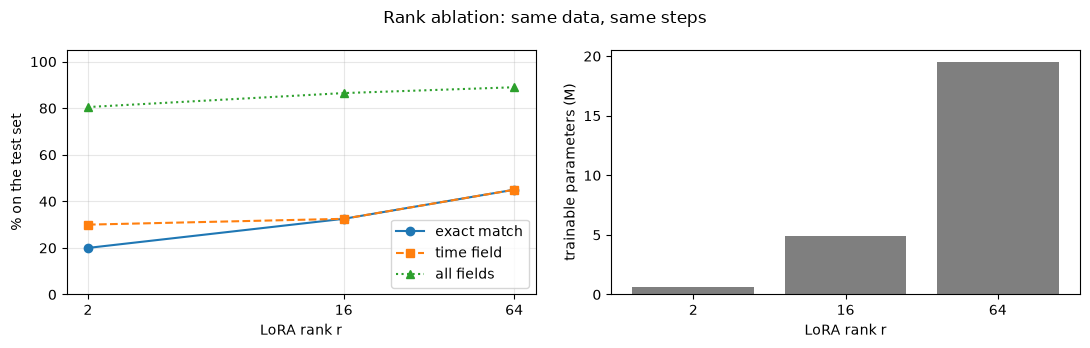

In [14]:
for r in [2, 64]:
    cfg = LoraConfig(r=r, lora_alpha=2 * r, target_modules="all-linear", task_type="CAUSAL_LM")
    trainer = train_sft(from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device), train_rows, f"LoRA r={r}",
                        peft_config=cfg, micro_batch=8 if r <= 16 else 4)     # same effective batch; r=64 needs more memory
    _ = evaluate(trainer.model, tok, f"LoRA r={r}")
    del trainer; free()

ranks = [2, 16, 64]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ranks, [100 * RESULTS[f"LoRA r={r}"]["exact"] for r in ranks], "o-", label="exact match")
ax[0].plot(ranks, [100 * RESULTS[f"LoRA r={r}"]["time"] for r in ranks], "s--", label="time field")
ax[0].plot(ranks, [100 * RESULTS[f"LoRA r={r}"]["fields"] for r in ranks], "^:", label="all fields")
ax[0].set_xscale("log", base=2); ax[0].set_xticks(ranks, [str(r) for r in ranks]); ax[0].set_ylim(0, 105)
ax[0].set_xlabel("LoRA rank r"); ax[0].set_ylabel("% on the test set"); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].bar([str(r) for r in ranks], [RUNS[f"LoRA r={r}"]["trainable"] / 1e6 for r in ranks], color="tab:gray")
ax[1].set_xlabel("LoRA rank r"); ax[1].set_ylabel("trainable parameters (M)")
fig.suptitle("Rank ablation: same data, same steps"); plt.tight_layout(); plt.show()

With the same data and steps, exact match rises with the rank here: 20 % (r = 2) → 32.5 % (r = 16) → 45 % (r = 64), almost all of it in the `time` field, and the training curves show r = 2 learning more slowly. Learning a new rule from 300 examples in 38 steps benefits from more adapter capacity. Two caveats: with 40 test requests each one is worth 2.5 points, so a difference of one or two requests is noise; and all three ranks stay far below what more data gives (next section). Common practice: start at r = 16 with `alpha = 2r` on all linear layers, and raise the rank only if the held-out metric asks for it.

## 7. Distillation: a bigger teacher labels the data

Labelled data is expensive, unlabelled prompts are cheap. **Knowledge distillation** transfers what a strong *teacher* knows into a small *student*. Two flavours:

- **Sequence-level (synthetic-data) distillation**: the teacher *writes the answers* to unlabelled prompts, and the student does ordinary SFT on them. This is how most small open models are made today (e.g. DeepSeek-R1-Distill, or fine-tuning on answers from a frontier API). It only needs the teacher's text.
- **Logit distillation**: the student matches the teacher's full next-token distribution at temperature τ, $\mathcal{L} = (1-\lambda)\,\mathrm{CE}(y, p_s) + \lambda\,\tau^2\,\mathrm{KL}(p_t^{\tau}\,\|\,p_s^{\tau})$. Denser signal ("dark knowledge": how likely every other token was), but it needs the teacher's logits and **the same tokenizer**. TRL implements the on-policy version (GKD) as `trl.DistillationTrainer`. We do not run it here to keep the notebook short.

#### The theory behind distillation

**Soft targets and temperature.** Hinton, Vinyals & Dean (2015) observed that a trained network's output distribution carries more information than its top answer: a teacher that gives "20:30" most of its probability and "20:00" a small but clear share is also saying which mistakes are plausible. To expose that information they soften both distributions with a temperature $\tau > 1$:
$$p_i^{\tau} = \frac{\exp(z_i / \tau)}{\sum_j \exp(z_j / \tau)}$$
where $z$ are the logits. At $\tau = 1$ this is the ordinary softmax; as $\tau$ grows the distribution flattens and the small probabilities ("dark knowledge") get a visible share of the loss. The student minimizes $\mathrm{KL}(p_t^\tau \,\|\, p_s^\tau)$ per token, usually mixed with the ordinary cross-entropy on the gold label, as in the formula above. The factor $\tau^2$ is there because the gradient of the softened KL with respect to the student logits scales as $1/\tau^2$; multiplying by $\tau^2$ keeps the two loss terms on comparable scales when you change $\tau$.

**Which direction of KL.** The forward KL $\mathrm{KL}(p_t \| p_s)$ is *mode-covering*: the student is penalized wherever the teacher has mass and it does not, so a small student spreads its probability over everything the teacher might say, including regions it cannot model well. The reverse KL $\mathrm{KL}(p_s \| p_t)$ is *mode-seeking*: the student is penalized for putting mass where the teacher has none, so it concentrates on the teacher's main modes. For generation, where sampling from a spread-out distribution produces incoherent text, MiniLLM (Gu et al., 2024) argued for the reverse KL; GKD (Agarwal et al., 2024) treats the divergence as a choice (including the generalized Jensen-Shannon divergence between the two) and trains on sequences sampled from the student itself. That "on-policy" part addresses exposure bias: the student learns what the teacher would do in the states the *student* actually reaches.

**Sequence-level distillation as an approximation.** Kim & Rush (2016) showed that training the student on the teacher's *decoded outputs* (beam search or greedy) works surprisingly well. You can read it as replacing the teacher's full distribution over sequences with its mode. You lose the dark knowledge, but you gain three things: it works across different tokenizers and architectures, it works with a teacher you can only reach through an API, and it is just SFT, so all the tooling above applies. This is why it dominates in practice (Alpaca, Vicuna and many reasoning distillations were built this way).

| | sequence-level (synthetic labels) | logit (token-level) | on-policy (GKD, MiniLLM) |
|---|---|---|---|
| needs from the teacher | text only | logits at every position | logits on student samples |
| tokenizer | any | must match (or be aligned) | must match |
| signal per example | one target sequence | a full distribution per token | a full distribution per token, on the student's own states |
| cost | one teacher generation per prompt | teacher forward pass per training step | student sampling + teacher forward per step |
| main risk | copies the teacher's errors | memory for two models | slow, more moving parts |

**Failure modes.** The student is bounded by the teacher and inherits its systematic errors (here, 10 % of the labels are wrong, and a teacher's errors are rarely random: they tend to repeat on the same kind of input). A large *capacity gap* can make a very strong teacher a worse teacher than a medium one, because the student cannot represent what it is shown (Mirzadeh et al., 2020, *Improved Knowledge Distillation via Teacher Assistant*). And when the teacher is a commercial API, check its terms of use: several providers forbid using outputs to train competing models.

Our setup: the teacher is **SmolLM2-360M-Instruct** fine-tuned with LoRA on the *same* 300 labelled examples. It then labels **600 new, unlabelled requests**, and the 135M student is trained on the 300 human labels plus the 600 teacher labels.

In [15]:
TEACHER = "HuggingFaceTB/SmolLM2-360M-Instruct"
teacher = from_pretrained(AutoModelForCausalLM, TEACHER, dtype=DTYPE).to(device)
cfg = LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM")
trainer = train_sft(teacher, train_rows, "teacher 360M LoRA r=16", peft_config=cfg, micro_batch=2)
teacher = trainer.model.merge_and_unload(); del trainer; free()
_ = evaluate(teacher, tok, "teacher 360M LoRA r=16")           # SmolLM2 135M and 360M share the same tokenizer

unlabelled = [x for x, _ in booking_examples(600, seed=7)]     # new requests; we pretend we do not know their answers
t0 = time.time()
teacher_replies = generate(teacher, tok, [to_prompt_completion(x, {})["prompt"] for x in unlabelled])
print(f"teacher labelled {len(unlabelled)} requests in {time.time() - t0:.0f} s")
hidden_gold = [y for _, y in booking_examples(600, seed=7)]   # only to measure the quality of the teacher's labels
print(f"teacher labels: {100*np.mean([parse_json(r) is not None for r in teacher_replies]):.1f}% valid JSON, "
      f"{100*np.mean([parse_json(r) == y for r, y in zip(teacher_replies, hidden_gold)]):.1f}% exactly right")
teacher_rows = [to_prompt_completion(x, parse_json(r)) for x, r in zip(unlabelled, teacher_replies) if parse_json(r) is not None]
del teacher; free()

cfg = LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM")
# One epoch over 300 + ~600 examples is 57 optimizer steps (vs 38 for the 135M runs above): 3x the data, 1.5x the steps.
trainer = train_sft(from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device), train_rows + teacher_rows,
                    "student 135M: human + teacher labels", peft_config=cfg, epochs=1)
_ = evaluate(trainer.model, tok, "student 135M: human + teacher labels", show=2)
del trainer; free()

teacher 360M LoRA r=16: 8.7 M trainable params, 38 steps, 230 s, peak VRAM 1.27 GB, final loss 0.012


teacher 360M LoRA r=16             valid 100.0% | exact  87.5% | fields  97.5% | time  92.5%


teacher labelled 600 requests in 104 s
teacher labels: 100.0% valid JSON, 90.0% exactly right


student 135M: human + teacher labels: 4.9 M trainable params, 57 steps, 87 s, peak VRAM 1.54 GB, final loss 0.027


student 135M: human + teacher labels valid 100.0% | exact  55.0% | fields  91.0% | time  55.0%
     {"name": "Noelia", "restaurant": "Asador Toro", "people": 4, "day": "thursday", "time": "13:00"}
     {"name": "Rocio", "restaurant": "Casa Lola", "people": 3, "day": "friday", "time": "21:00"}


**What happened.** Trained on the *same* 300 human labels, the 360M teacher reaches 87.5 % exact (92.5 % on `time`): the bigger model learns the conversion rule from data that was not enough for the 135M model. Its labels for the 600 new requests are 90 % exactly right. The 135M student trained on human + teacher labels goes from 32.5 % (human labels only, LoRA r = 16) to **55 %** exact. Two honest caveats: the comparison is not perfectly controlled (the student also took 57 optimizer steps instead of 38), and the student still trails its teacher and has learned from labels that are 10 % wrong. In real projects you cannot compute that 90 % for free as we did here: spot-check a sample of the teacher's labels, or filter them with a verifier (here, a JSON schema check would catch format errors but not a wrong hour).

## 8. Model merging: combining fine-tunes without training

You now have several adapters trained from the same base: one per task, per customer or per experiment. **Model merging** combines them into one set of weights with arithmetic alone, with no data and no GPU training. It is how many top open-weight models on public leaderboards were built (with `mergekit`), and how teams fold a specialist adapter back into a general model.

### The idea: fine-tunes are vectors

Fine-tuning moves the weights from $\theta_0$ to $\theta_t$. Ilharco et al. (2023, *Editing Models with Task Arithmetic*) call the difference a **task vector**, $\tau_t = \theta_t - \theta_0$, and showed that you can do arithmetic with it:

$$\theta_{\text{merged}} = \theta_0 + \sum_t \lambda_t\, \tau_t$$

Adding two task vectors gives a model that does both tasks, often nearly as well as each specialist. Subtracting one ($\lambda < 0$) removes a behaviour: the paper used it to make a model less toxic. With LoRA, the task vector of each adapted matrix is just $\Delta W = \frac{\alpha}{r} BA$.

### Why it works at all

Weights are not normally additive: average two networks trained from different random initializations and you get a broken model, because their neurons are permuted relative to each other. Fine-tunes of the *same* pretrained model are different. They stay in the same basin of the loss landscape, connected by a straight path along which the loss stays low (*linear mode connectivity*, Frankle et al., 2020; Neyshabur et al., 2020). Wortsman et al. (2022, *Model soups*) used this to average fine-tunes of one task with different hyperparameters and got better accuracy and robustness than the best single run, for free at inference time.

For different tasks, merging works when the task vectors interfere little. In a model with millions of parameters per matrix, two unrelated updates are nearly **orthogonal** (cosine similarity close to 0), so adding one barely disturbs the other. We measure that below.

### When they interfere: TIES and DARE

When task vectors overlap, plain addition goes wrong in two ways: small, noisy coordinates add up, and coordinates where the tasks pull in opposite directions cancel out or overshoot. Two methods address this.

- **TIES-Merging** (Yadav et al., 2023) works in three steps:
  1. *Trim*: keep only the largest-magnitude fraction (the *density*) of each task vector.
  2. *Elect sign*: for each coordinate, choose the sign with the larger total magnitude.
  3. *Disjoint merge*: average only the values that agree with that sign.
- **DARE** (Yu et al., 2024, *Language Models are Super Mario*) randomly drops a fraction $p$ of each task vector's coordinates and rescales the rest by $1/(1-p)$, which keeps the expected update the same. It found that fine-tuning updates are so redundant that 90 % or more can be dropped, and it is usually combined with TIES' sign election (`dare_ties`).

Other popular methods: **SLERP** interpolates two models along the sphere instead of a straight line (two models only), and **LoraHub** (Huang et al., 2023) learns the mixing weights from a few examples.

### Merging LoRA adapters: the factor trap

A LoRA adapter stores $B$ and $A$, not $\Delta W$, and $\big(B_1 + B_2\big)\big(A_1 + A_2\big) = B_1 A_1 + B_2 A_2 + \underbrace{B_1 A_2 + B_2 A_1}_{\text{cross terms}}$. Summing the factors therefore adds two cross terms that neither task asked for. `peft`'s `add_weighted_adapter` offers several merging methods:

| `combination_type` | what it computes | exact? |
|---|---|---|
| `linear` | sums the $A$ factors and the $B$ factors separately | no, adds the cross terms (the docs call it "a very rough approximation") |
| `cat` | concatenates the factors: rank $r_1 + r_2$, $\Delta W = \sum_t \lambda_t \Delta W_t$ | yes, this is task arithmetic |
| `svd` | forms $\sum_t \lambda_t \Delta W_t$, then compresses it back to a chosen rank with an SVD | exact if `svd_rank` ≥ the rank of the sum |
| `ties_svd`, `dare_ties_svd`, ... | TIES or DARE on the full $\Delta W$, then an SVD | the method's own approximation |

### The experiment

We train a second adapter on a different task, **converting a time to 24-hour format** ("8:30 pm" → "20:30"), on 300 examples. It is a skill the booking adapter only half learned (its `time` field is its main error). Then we compare, on *both* tasks:
- the booking adapter alone and the time adapter alone;
- four merges of the two, all with weights 1 and 1 (`linear`, `cat`, `ties_svd`, `dare_ties_svd`);
- the usual alternative to merging, one **multi-task** adapter trained on both datasets together.

We also check whether merging transfers the conversion skill into the booking task.

### Key papers

- Frankle, Dziugaite, Roy & Carbin (2020), *Linear Mode Connectivity and the Lottery Ticket Hypothesis*.
- Wortsman et al. (2022), *Model soups: averaging weights of multiple fine-tuned models improves accuracy without increasing inference time*.
- Ilharco et al. (2023), *Editing Models with Task Arithmetic*.
- Yadav et al. (2023), *TIES-Merging: Resolving Interference When Merging Models*.
- Yu et al. (2024), *Language Models are Super Mario: Absorbing Abilities from Homologous Models as a Free Lunch* (DARE).
- Huang et al. (2023), *LoraHub: Efficient Cross-Task Generalization via Dynamic LoRA Composition*.
- Goddard et al. (2024), *Arcee's MergeKit: A Toolkit for Merging Large Language Models*.

In [16]:
# A second, different task: convert a time to 24-hour format. Same generator of time phrasings as the bookings.
TIME_SYSTEM = "Convert the time to 24-hour format. Reply with HH:MM only."
def time_examples(n, seed):
    rng = random.Random(seed); out = []
    for _ in range(n):
        h, m = rng.randint(13, 22), rng.choice([0, 0, 15, 30, 45])
        out.append((time_text(h, m, rng), f"{h:02d}:{m:02d}"))
    return out
def time_row(x, y):
    return {"prompt": [{"role": "system", "content": TIME_SYSTEM}, {"role": "user", "content": x}],
            "completion": [{"role": "assistant", "content": y}]}
time_train, time_test = time_examples(300, seed=3), time_examples(40, seed=4)
time_rows = [time_row(x, y) for x, y in time_train]
print(time_rows[0]["prompt"][1]["content"], "->", time_rows[0]["completion"][0]["content"])

def time_accuracy(model):
    replies = generate(model, tok, [time_row(x, y)["prompt"] for x, y in time_test], max_new_tokens=10)
    found = [re.search(r"\b\d{1,2}:\d{2}\b", r) for r in replies]
    return np.mean([f is not None and f.group(0) == y for f, (_, y) in zip(found, time_test)])

MERGE = {}        # name -> metrics on both tasks
def both_tasks(model, name):
    _ = evaluate(model, tok, name)                    # the booking test set (prints one line)
    MERGE[name] = dict(RESULTS[name], time_task=time_accuracy(model))
    print(f"{'':34s} time-conversion task {100 * MERGE[name]['time_task']:5.1f}%")

cfg = LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM")
trainer = train_sft(from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device), time_rows, "LoRA r=16, time task", peft_config=cfg)
time_dir = os.path.join(OUT, "lora_time"); trainer.model.save_pretrained(time_dir)
del trainer; free()

# The alternative to merging: one adapter trained on both datasets (600 rows, so twice the steps of each specialist).
cfg = LoraConfig(r=16, lora_alpha=32, target_modules="all-linear", task_type="CAUSAL_LM")
trainer = train_sft(from_pretrained(AutoModelForCausalLM, MODEL, dtype=DTYPE).to(device), train_rows + time_rows,
                    "multi-task LoRA (both datasets)", peft_config=cfg)
both_tasks(trainer.model, "multi-task LoRA (both datasets)")
del trainer; free()

4:45 pm -> 16:45


LoRA r=16, time task: 4.9 M trainable params, 38 steps, 56 s, peak VRAM 0.90 GB, final loss 0.046


multi-task LoRA (both datasets): 4.9 M trainable params, 76 steps, 115 s, peak VRAM 1.52 GB, final loss 0.024


multi-task LoRA (both datasets)    valid 100.0% | exact  55.0% | fields  89.5% | time  70.0%


                                   time-conversion task  97.5%


In [17]:
from peft import PeftModel
import torch.nn.functional as F

# fp32 for this section: the SVD-based merges need it. The two adapters are loaded side by side on one base model.
pm = PeftModel.from_pretrained(from_pretrained(AutoModelForCausalLM, MODEL, dtype=torch.float32).to(device), adapter_dir, adapter_name="booking")
pm.load_adapter(time_dir, adapter_name="time")
torch.manual_seed(0)                                   # DARE drops coordinates at random
METHODS = {"linear": {}, "cat": {}, "ties_svd": {"density": 0.5, "svd_rank": 32}, "dare_ties_svd": {"density": 0.5, "svd_rank": 32}}
t0 = time.time()
for method, kw in METHODS.items():
    pm.add_weighted_adapter(["booking", "time"], [1.0, 1.0], adapter_name=method, combination_type=method, **kw)
print(f"4 merges computed in {time.time() - t0:.1f} s, no data and no training")

# How much do the two task vectors interfere? Compare them matrix by matrix.
def delta(m, name):
    return (m.lora_B[name].weight @ m.lora_A[name].weight) * m.scaling[name]
mods = [m for m in pm.modules() if hasattr(m, "lora_A") and "booking" in m.lora_A]
cos, conflict, err = [], [], {k: [] for k in METHODS}
with torch.no_grad():
    for m in mods:
        a, b = delta(m, "booking"), delta(m, "time")
        cos.append(F.cosine_similarity(a.flatten(), b.flatten(), dim=0).item())
        big = (a.abs() > a.abs().median()) & (b.abs() > b.abs().median())       # coordinates where both updates are large
        conflict.append((a.sign() != b.sign())[big].float().mean().item())
        for k in METHODS:
            err[k].append(((delta(m, k) - (a + b)).norm() / (a + b).norm()).item())
print(f"{len(mods)} adapted matrices | cosine(booking, time) per matrix: mean {np.mean(cos):+.3f}, max |cos| {np.max(np.abs(cos)):.3f}")
print(f"sign conflicts where both updates are large: {100 * np.mean(conflict):.0f}% (50% would be unrelated directions)")
for k in METHODS:
    print(f"  {k:14s} distance from the exact sum of the two updates: {100 * np.mean(err[k]):5.1f}% (relative norm)")

4 merges computed in 19.2 s, no data and no training


210 adapted matrices | cosine(booking, time) per matrix: mean +0.012, max |cos| 0.095
sign conflicts where both updates are large: 49% (50% would be unrelated directions)
  linear         distance from the exact sum of the two updates:  91.0% (relative norm)
  cat            distance from the exact sum of the two updates:   0.0% (relative norm)
  ties_svd       distance from the exact sum of the two updates:  36.6% (relative norm)
  dare_ties_svd  distance from the exact sum of the two updates:  49.6% (relative norm)


booking adapter only               valid 100.0% | exact  32.5% | fields  86.5% | time  32.5%


                                   time-conversion task  27.5%


time adapter only                  valid   0.0% | exact   0.0% | fields   0.0% | time   0.0%


                                   time-conversion task  97.5%


merge: linear                      valid 100.0% | exact  27.5% | fields  83.5% | time  27.5%


                                   time-conversion task  87.5%


... (4 outputs left out)

merge: dare_ties_svd               valid 100.0% | exact  30.0% | fields  84.0% | time  37.5%


                                   time-conversion task  87.5%


base model, no adapter             valid   2.5% | exact   0.0% | fields   1.0% | time   0.0%


                                   time-conversion task  30.0%


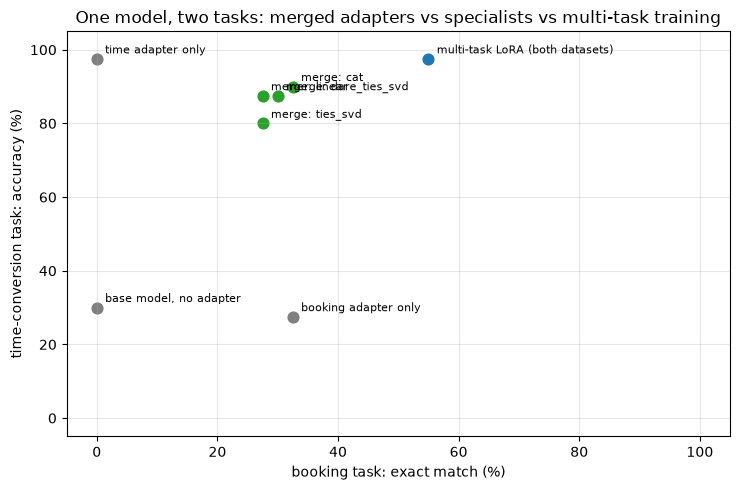

In [18]:
# The merges were computed in fp32; we evaluate in bf16 like every other model in this notebook (and it fits the VRAM budget).
pm = pm.to(DTYPE); free()
pm.set_adapter("booking"); both_tasks(pm, "booking adapter only")
pm.set_adapter("time");    both_tasks(pm, "time adapter only")
for method in METHODS:
    pm.set_adapter(method); both_tasks(pm, f"merge: {method}")
with pm.disable_adapter():
    both_tasks(pm, "base model, no adapter")
del pm; free()

names = list(MERGE)
fig, ax = plt.subplots(figsize=(7.5, 5))
for n in names:
    x, y = 100 * MERGE[n]["exact"], 100 * MERGE[n]["time_task"]
    ax.scatter(x, y, s=60, color="tab:green" if n.startswith("merge") else "tab:blue" if "multi" in n else "tab:gray")
    ax.annotate(n, (x, y), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("booking task: exact match (%)"); ax.set_ylabel("time-conversion task: accuracy (%)")
ax.set_xlim(-5, 105); ax.set_ylim(-5, 105); ax.grid(alpha=.3)
ax.set_title("One model, two tasks: merged adapters vs specialists vs multi-task training")
plt.tight_layout(); plt.show()

**What the numbers say.**

- **The two task vectors barely overlap.** Across the 210 adapted matrices their average cosine similarity is +0.012 (the largest 0.095), and where both updates are large their signs agree half the time, which is what unrelated directions give. This is the condition under which plain addition should work, and it does.
- **Task arithmetic (`cat`) is the best merge.** One set of weights keeps the booking task intact (32.5 % exact, the same as the booking adapter alone, and 85.0 % of fields against 86.5 %) and converts times at 90.0 %: the specialist gets 97.5 % and the base model 30.0 %. All four merges took 19 s of arithmetic, with no data and no training.
- **`linear` loses on both tasks** (27.5 % and 87.5 %). Its merged update is 91 % away from the exact sum of the two: those are the cross terms $B_1A_2 + B_2A_1$, a change neither task asked for.
- **TIES and DARE did not help** (27.5 % / 80.0 % and 30.0 % / 87.5 %). They are designed to resolve interference, and here there was none to resolve, so keeping half the coordinates (density 0.5) only threw signal away; their updates are 37 % and 50 % away from the exact sum. They earn their keep when merging many overlapping fine-tunes, for example full chat models fine-tuned from the same base.
- **Merging did not transfer the skill.** The merged models keep the booking `time` field at 32.5–37.5 %, no better than the booking adapter alone (one or two requests, within the noise). The time adapter learned to convert *when the prompt asks for a conversion*, not inside a JSON extraction. Merging puts two behaviours in one model; it does not combine them into a new one.
- **Multi-task training wins when you can do it**: 55.0 % exact, 70.0 % on the `time` field and 97.5 % on time conversion, better than every merge on both tasks. When the two datasets are trained together, the conversion skill *does* carry over into the booking task. It used 76 steps (as many as the two specialists together) and needs both datasets at once.

So: train one multi-task model when you own all the data. Merge when you cannot, for example when the adapters come from different teams or from the Hub, the data is no longer available, or there is no budget to retrain. For LoRA use `cat` or `svd` (exact), never `linear`, and evaluate the merge on *every* task it should keep.

## 9. Evaluation

Every model on the same 40 held-out requests, plus what each training run cost.

model                                   valid  exact  fields   time |  trainable  train s  peak GB
baseline zero-shot                         5%     0%      2%     0% |          -        -        -
baseline few-shot                        100%    18%     73%    25% |          -        -        -
full SFT                                 100%    35%     86%    38% |    134.5 M       72     1.19
LoRA r=2                                 100%    20%     80%    30% |      0.6 M       58     1.46
LoRA r=16                                100%    32%     86%    32% |      4.9 M       63     1.41
QLoRA r=16 (NF4)                         100%    38%     86%    45% |      4.9 M       72     1.34
LoRA r=64                                100%    45%     89%    45% |     19.5 M      109     1.25
teacher 360M LoRA r=16                   100%    88%     98%    92% |      8.7 M      230     1.27
student 135M: human + teacher labels     100%    55%     91%    55% |      4.9 M       87     1.54


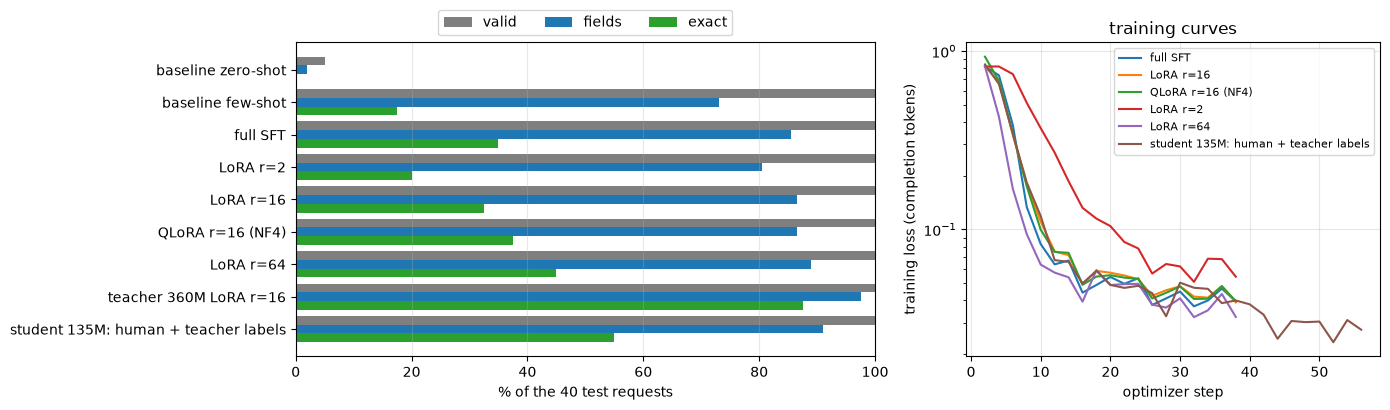

In [19]:
order = [n for n in ["baseline zero-shot", "baseline few-shot", "full SFT", "LoRA r=2", "LoRA r=16", "QLoRA r=16 (NF4)", "LoRA r=64",
                     "teacher 360M LoRA r=16", "student 135M: human + teacher labels"] if n in RESULTS]
print(f"{'model':38s} {'valid':>6s} {'exact':>6s} {'fields':>7s} {'time':>6s} | {'trainable':>10s} {'train s':>8s} {'peak GB':>8s}")
for n in order:
    r, run = RESULTS[n], RUNS.get(n)
    cost = f"{run['trainable']/1e6:8.1f} M {run['time']:8.0f} {run['peak']:8.2f}" if run else f"{'-':>10s} {'-':>8s} {'-':>8s}"
    print(f"{n:38s} {100*r['valid']:5.0f}% {100*r['exact']:5.0f}% {100*r['fields']:6.0f}% {100*r['time']:5.0f}% | {cost}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.4, 1]})
ys = np.arange(len(order)); w = 0.27
for k, (metric, c) in enumerate([("valid", "tab:gray"), ("fields", "tab:blue"), ("exact", "tab:green")]):
    ax[0].barh(ys + (k - 1) * w, [100 * RESULTS[n][metric] for n in order], height=w, color=c, label=metric)
ax[0].set_yticks(ys, order); ax[0].invert_yaxis(); ax[0].set_xlim(0, 100); ax[0].set_xlabel("% of the 40 test requests")
ax[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3); ax[0].grid(alpha=.3, axis="x")
for n in ["full SFT", "LoRA r=16", "QLoRA r=16 (NF4)", "LoRA r=2", "LoRA r=64", "student 135M: human + teacher labels"]:
    steps, loss = zip(*RUNS[n]["loss"])
    ax[1].plot(steps, loss, label=n)
ax[1].set_yscale("log"); ax[1].set_xlabel("optimizer step"); ax[1].set_ylabel("training loss (completion tokens)")
ax[1].set_title("training curves"); ax[1].grid(alpha=.3); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the results.**
1. Fine-tuning beats the best prompt: few-shot gets 17.5 % exact; 300 examples and under a minute of training get 32–45 %, and every fine-tuned model writes valid JSON 100 % of the time.
2. LoRA (3.5 % of the parameters) is within one test request of full fine-tuning.
3. The biggest levers were **model size** (the 360M teacher: 87.5 %) and **more data**, even machine-labelled (the student: 55 %). Rank came next (20 → 45 %).
4. The per-field view says where to go next: almost all remaining errors are in `time`. That tells you to add examples of exactly that conversion, rather than more data in general.
5. The training curves end at similar losses (0.03–0.05) while held-out exact match ranges from 20 % to 45 %. Training loss alone does not tell you task accuracy.

With 40 test requests, each request is 2.5 points: treat differences of one or two requests as noise, and use a larger test set before making a real decision.

### What to measure in a real project

| check | why |
|---|---|
| exact match / task accuracy on *your* held-out set (built before training) | did it learn the task? |
| per-field or per-category breakdown | where are the remaining errors? (here: `time`) |
| JSON validity, or constrained decoding (`outlines`, `xgrammar`) | structured output must never break the caller |
| general benchmarks before/after (`lm-eval-harness`: MMLU, IFEval…) | catastrophic forgetting |
| training loss *and* held-out metric | a low training loss alone hides overfitting |

## Takeaways

- Use the model's **chat template** and mask the prompt: train only on the answer and its end-of-turn token. `trl.SFTTrainer` does it for prompt-completion data; check the labels once, as we did.
- Measure a **few-shot baseline** first. Fine-tuning has to beat a good prompt, not a bad one.
- **LoRA** (`target_modules="all-linear"`, a higher LR) trains a few % of the parameters, fits where full fine-tuning does not, merges back for free, and on small data is as good as full fine-tuning.
- **QLoRA** keeps the frozen base in 4-bit NF4 and trains bf16 adapters on top: the recipe for models whose bf16 weights do not fit (a 7B model drops from ~14 GB to ~3.6 GB of weights), at the price of slower steps. Merge into a bf16 copy of the base, not into the 4-bit weights.
- **New tokens + frozen embeddings cannot work** with tied embeddings and mean initialization: make the embedding trainable (`modules_to_save` or `trainable_token_indices`).
- **Rank** helped here (20 → 45 % from r = 2 to r = 64), but much less than more data did. Start at r = 16 and let the held-out metric decide.
- **Sequence-level distillation**: a stronger teacher turns cheap unlabelled prompts into training data. The student is bounded by the teacher's mistakes, so measure the teacher's labels.
- **Model merging**: adapters from the same base can be added with task arithmetic (`cat`, exact) when their task vectors are nearly orthogonal. Merging keeps both behaviours, but multi-task training on both datasets did better on both tasks and transferred the skill between them.

## Results

All numbers on the same 40 held-out booking requests (SmolLM2-135M-Instruct, RTX 3060 Laptop, 300 labelled examples).

| experiment | result | lesson |
|---|---|---|
| prompting baseline | zero-shot 0 % exact (5 % valid JSON); few-shot 17.5 % exact, 73 % of fields | fine-tuning has to beat a good prompt |
| full SFT | 35.0 % exact, 85.5 % fields, 100 % valid JSON; 134.5M trainable parameters, 72 s | 300 examples double the best prompt |
| LoRA r = 16 | 32.5 % exact, 86.5 % fields; 3.5 % of the parameters, a 19.6 MB adapter; merges back with logits within 1e-4 | within one request of full fine-tuning |
| QLoRA r = 16 (NF4) | 37.5 % exact, 86.5 % fields; weights 269 → 110 MB; 72 s vs 63 s | no loss of quality from the 4-bit base |
| new special token | frozen embeddings: emitted 0 % of the time (rank ~24,000); `modules_to_save`: 100 % | train the embedding row of any new token |
| rank ablation | r = 2: 20 %, r = 16: 32.5 %, r = 64: 45 % exact | rank helps a little, data helps more |
| distillation | 360M teacher 87.5 %; its labels 90 % right; 135M student 32.5 → **55 %** | cheap machine labels from a stronger model |
| model merging | task arithmetic keeps booking at 32.5 % and converts times at 90 % (specialist 97.5 %); `linear`, TIES and DARE are worse; multi-task training 55 % + 97.5 % | merge when you cannot retrain; train together when you can |

What this establishes: the full workflow for adapting an open model to a narrow task, measured end to end. Parameter-efficient methods match full fine-tuning at a fraction of the memory. The biggest levers were model size and data, not the training method. And the failure modes covered here (an untrained new token, a merge that silently breaks a task) only show up if you measure each task separately.

## In production

**The recipe.**
- Build a held-out set before training.
- Measure a few-shot baseline.
- Start with LoRA r = 16 on all linear layers, learning rate around 1e-4 to 1e-3, prompt-completion data with the model's chat template.
- Use QLoRA only when the bf16 base does not fit.
- Go to full fine-tuning only when LoRA plateaus and you have the memory.
- Libraries: TRL's `SFTTrainer` + `peft` here; Unsloth or Axolotl wrap the same pieces with faster kernels and YAML configs; `torchtune` is PyTorch's own.

**Data beats knobs.** Look at the per-field errors and add examples of exactly what fails. If labels are scarce, distil from a stronger model (an open model you are allowed to use, or an API whose terms permit it). Spot-check the teacher's labels, or filter them with a verifier.

**Serving adapters.**
- With one task, merge the adapter into a bf16 base: no latency cost.
- With many tasks or customers, serve one base model with many adapters loaded on demand. vLLM (`--enable-lora`), SGLang and LoRAX batch requests for different adapters together.
- An adapter is a 20 MB artifact: version it with the base model it was trained on, the data and the evaluation results.
- To combine adapters you cannot retrain together, merge with task arithmetic (`cat` / `svd` in `peft`, or `mergekit` for full models), then run every task's evaluation on the merge.

**What to monitor.**
- Exact match and per-field accuracy on a frozen test set, plus JSON validity, or use constrained decoding so validity is guaranteed.
- General capabilities before and after (`lm-eval-harness`, IFEval) to catch forgetting.
- The drift between your production inputs and your training data, such as new restaurants, new time formats or other languages.

**Failure modes.**
- Learning rate too low for LoRA.
- Training on the prompt tokens.
- A new token that the frozen embeddings cannot emit.
- Merging an adapter into a different base than the one it was trained on, or merging LoRA factors with `linear`.
- A teacher's systematic errors copied by the student.
- Trusting the training loss: here, runs with the same final loss differ by 25 points of exact match.

**Next:** `14_preference_rl_dpo_grpo.ipynb`: DPO and GRPO with TRL.